In [1]:
%load_ext autoreload
%autoreload 2

#### Case 1 : XANES + PDF 

This notebook runs through a simple example of the capabilities of Spectra-Scope. The imported data is simulated XANES and PDF of Ti-Oxide structures from the materials project database and Na Narong, *et al.* [1]. This notebook runs through regressing bond length for this dataset.

In [19]:
from spectrascope.SpectraScope import *
from spectrascope.Features import * 
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from spectrascope.FusedLasso import FusedLasso
import SPA 
from spectrascope.SSPlotting import * 
from matplotlib import gridspec
plt.style.use('../ss.mplstyle')

Load Test files 

In [4]:
fnX = '../tests/test_files/X_testfile.npy'
fny = '../tests/test_files/y_testfile.npy'
X = np.load(fnX)
y = np.load(fny)

print('The shape of the input file is:', X.shape)
print('X[0] accesses the PDF data. X[1] accesses the XANES data.\n')
print('The shape of the label file is:', y.shape)


The shape of the input file is: (2, 821, 200)
X[0] accesses the PDF data. X[1] accesses the XANES data.

The shape of the label file is: (821,)


Initialize Spectra-Scope object

In [5]:
ss = SpectraScope(X = X, y = y, specnames=['pdf', 'xanes'], yname='nn', random_seed=12)

saving to /examples/models, change save_path kwarg if youd like to change


Adding the x-axis values for each dataset

In [6]:
ss.add_x_axis(specname='xanes', value=np.linspace(4969.0, 5021.0, 200))
ss.add_x_axis(specname='pdf', value=np.linspace(0,10,200))

The `SpectraScope.add_spectral_feature` function generates a feature from the uploaded data. The feature is selected by the `feat` parameter. `pontwise_features` generates interpolated data along the x-axis. 

In [7]:
ss.add_spectral_feature(specname = 'xanes', feat = 'pointwise_features', xrange = ss.xanes_xaxis)
ss.add_spectral_feature(specname = 'pdf', feat = 'pointwise_features', xrange = ss.pdf_xaxis)

Here, we plot the first XANES/PDF from each dataset. 

Text(0, 0.5, '$\\mu(E)$')

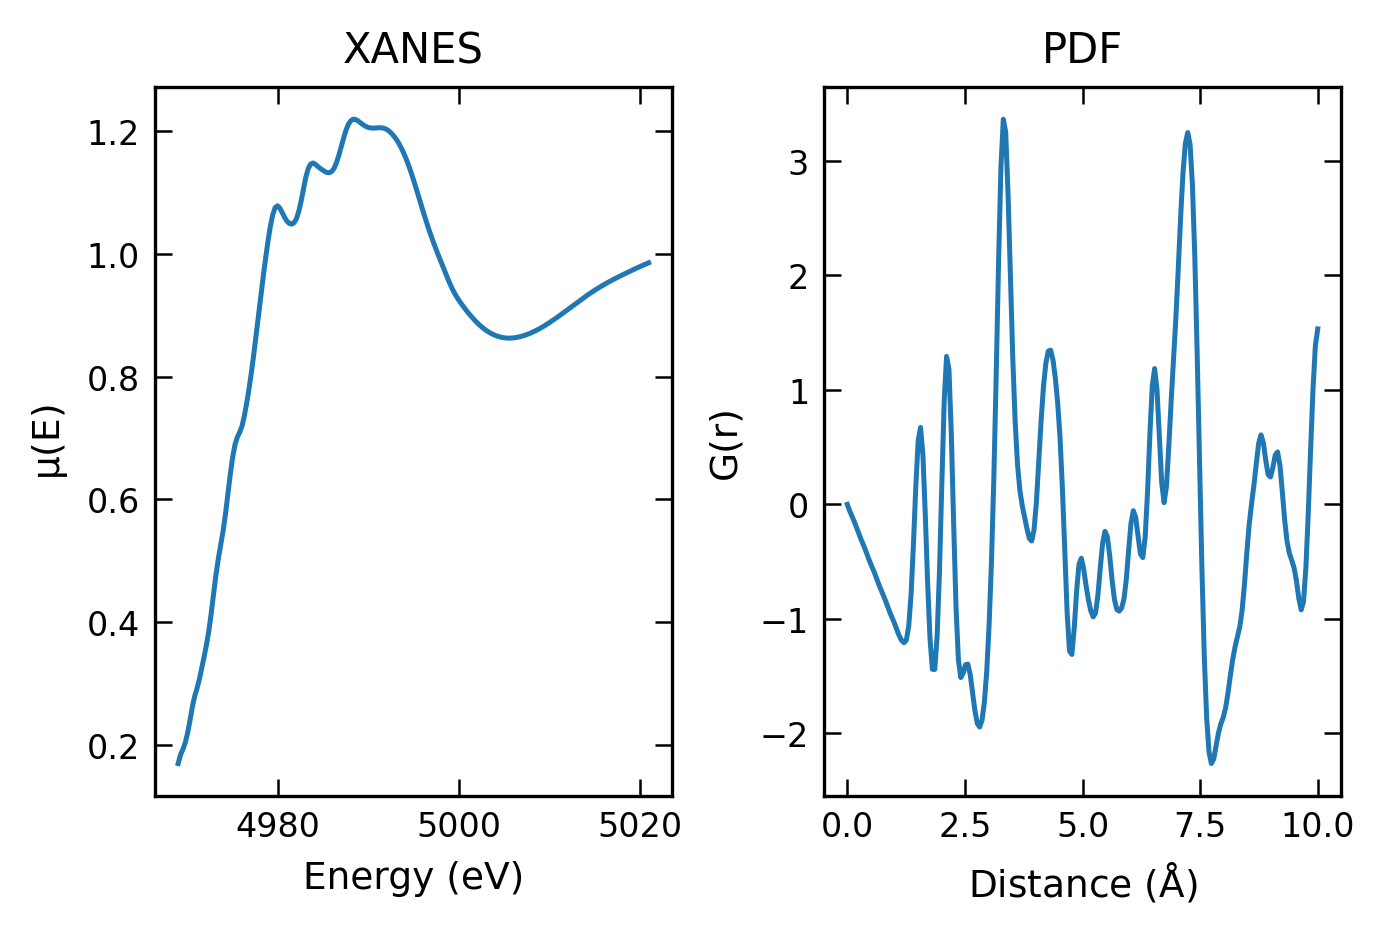

In [8]:
f, (ax1, ax2) = plt.subplots(1,2, constrained_layout=True)
ax1.plot(ss.xanes_xaxis, ss.xanes_pointwise_features[0])
ax2.plot(ss.pdf_xaxis, ss.pdf_pointwise_features[0])
ax1.set_title('XANES')
ax2.set_title('PDF')
ax1.set_xlabel('Energy (eV)')
ax2.set_xlabel(r'Distance ($\AA$)')
ax2.set_ylabel('G(r)')
ax1.set_ylabel(r'$\mu(E)$')


In [9]:
col = 'xanes'
spec = getattr(ss, f"{col}_pointwise_features")[0]
temp = SpectralFeatures(ss.xanes_xaxis, spec)

We will transform the different datasets in a variety of ways to compare model performance on different featurization schemes. Here, we featurize the XANES dataset in a variety of ways, again using the `SpectraScope.add_spectral_feature` function. 

In [10]:
ss.add_spectral_feature('xanes', 'polynomial_featuresall')
ss.add_spectral_feature('xanes', 'polynomial_featuresN', N=5)
ss.add_spectral_feature('xanes', 'featureagg', n_clusters=10)
ss.add_spectral_feature('xanes', 'pca', n_components=10)
ss.add_spectral_feature('xanes', 'cdf')
ss.add_spectral_feature('xanes', 'cwt')

Text(0.5, 0.98, 'XANES Featurization Schemes')

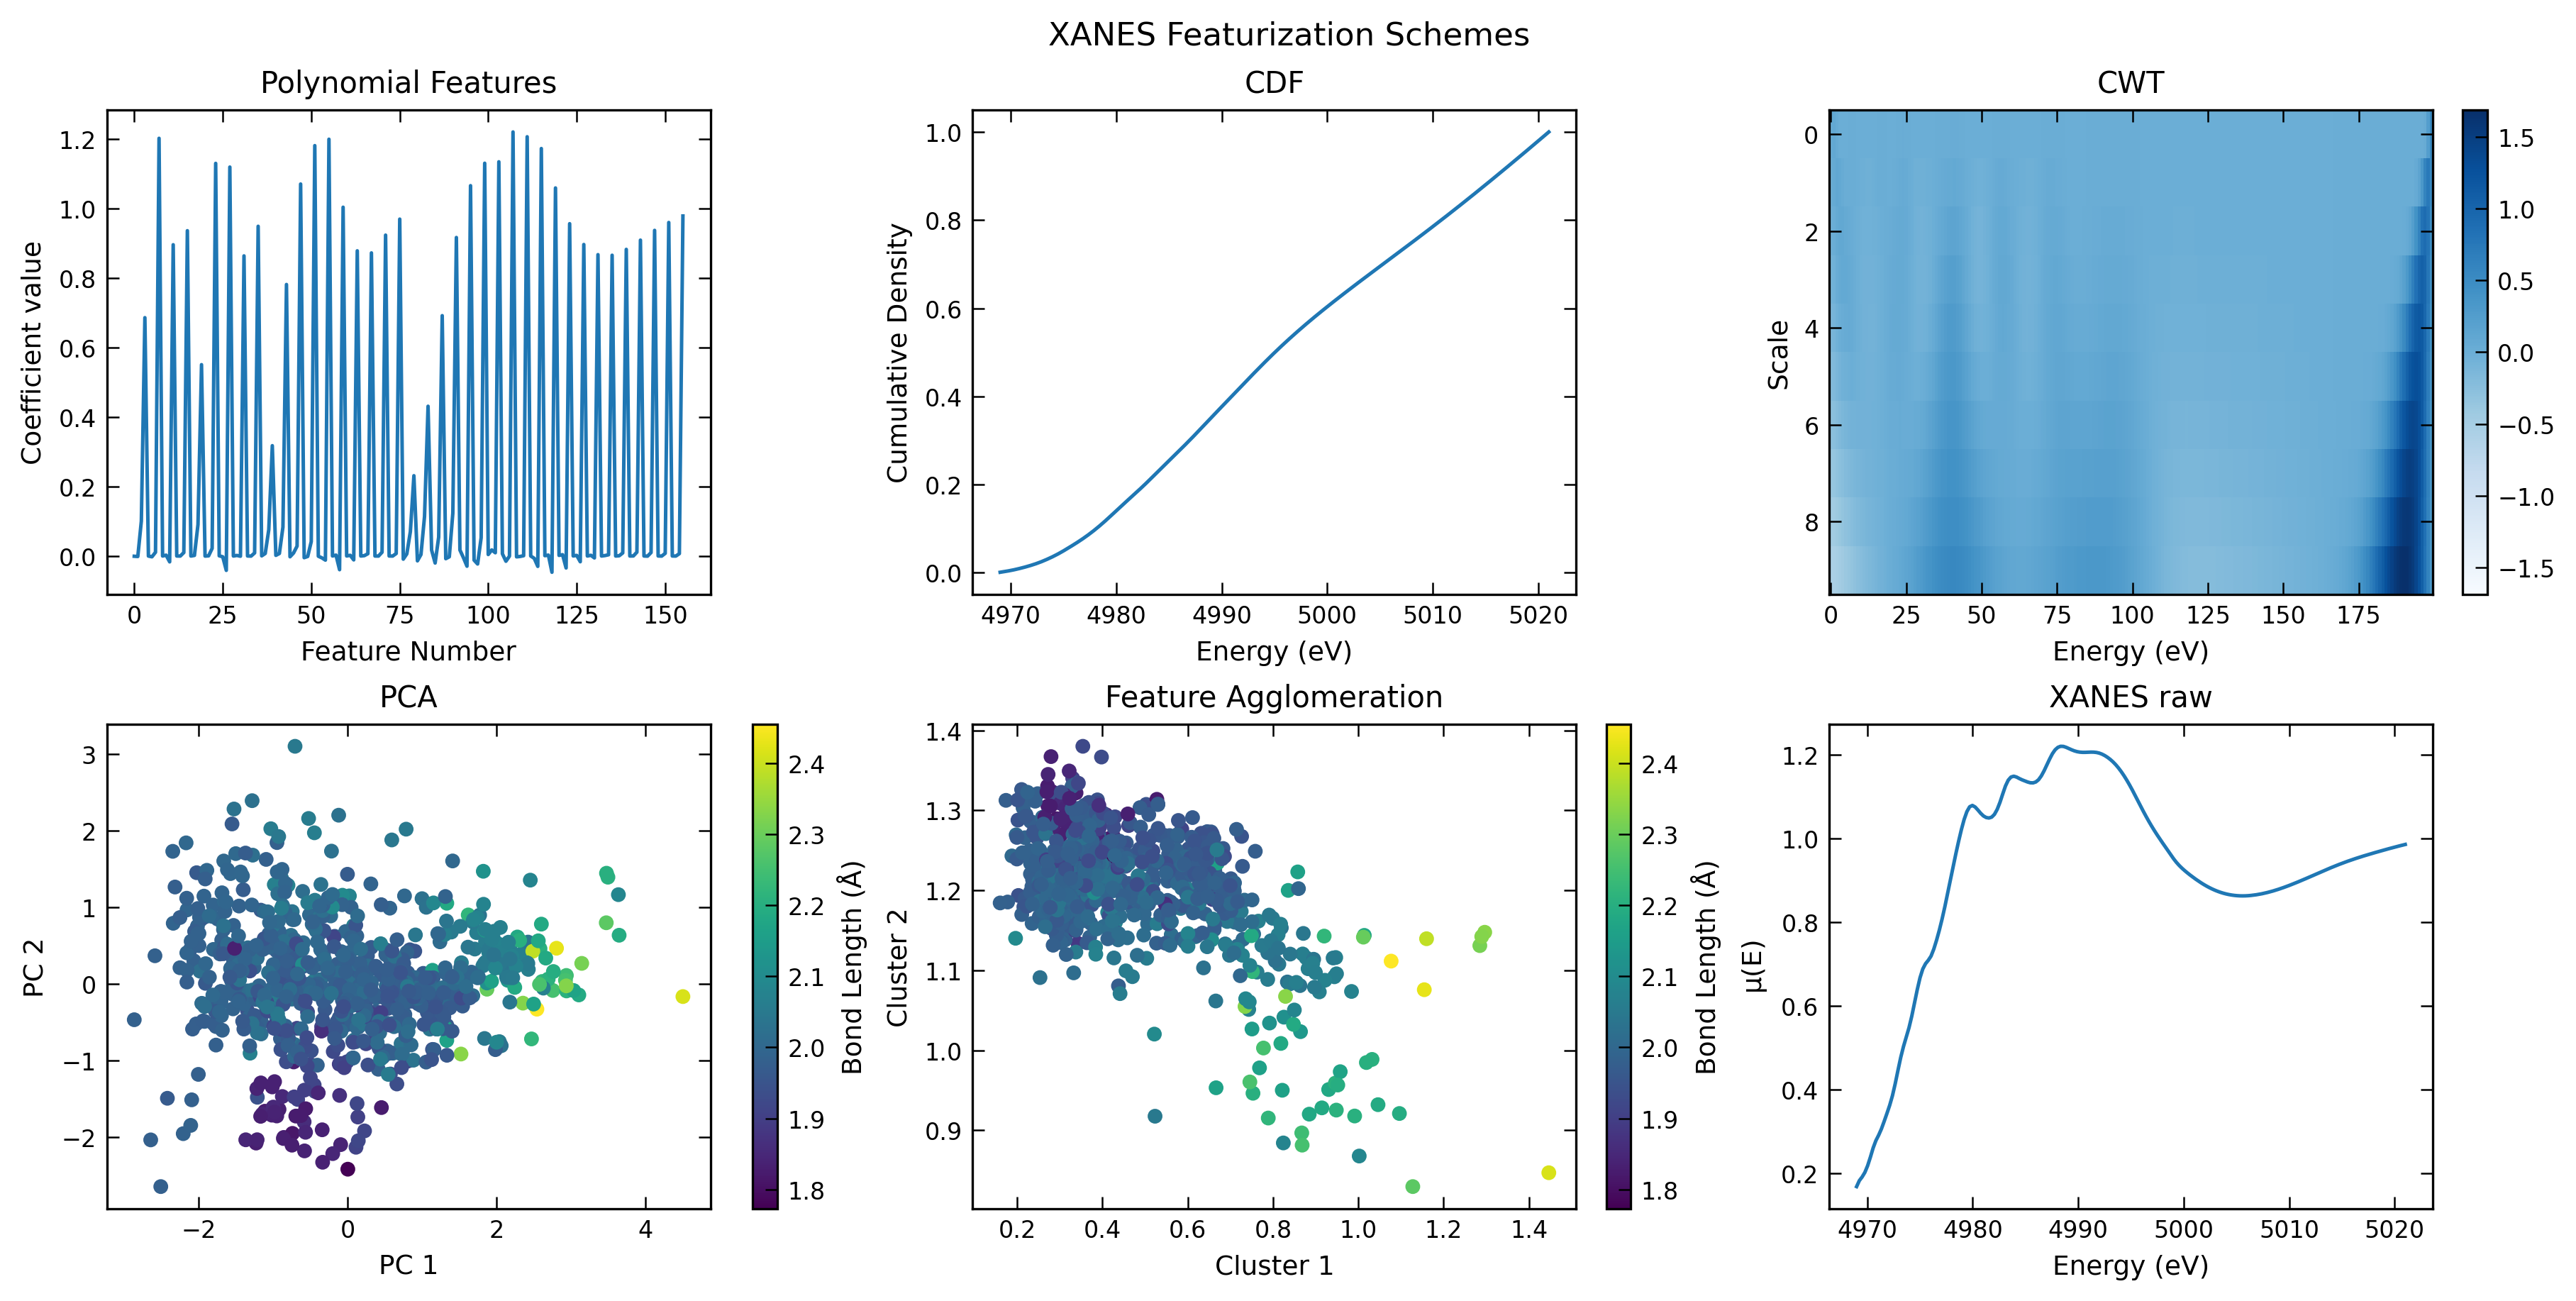

In [ ]:
f, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2,3, figsize=(12,6), constrained_layout = True)
ax1.plot(np.arange(156), ss.xanes_polynomial_featuresall[0][:-1])
ax2.plot(ss.xanes_xaxis, ss.xanes_cdf[0])

cwt_coefs = ss.xanes_cwt[0]
im = ax3.imshow(cwt_coefs.reshape(10,200), aspect='auto', cmap='Blues',
                vmax=(np.abs(cwt_coefs)).max(), vmin=-(np.abs(cwt_coefs)).max())
f.colorbar(im, ax=ax3)


pc = ax4.scatter(ss.xanes_pca[:,0], ss.xanes_pca[:,1], c = ss.nn, )
f.colorbar(pc, ax=ax4, label='Bond Length (Å)')
agg = ax5.scatter(ss.xanes_featureagg[:,0], ss.xanes_featureagg[:,1], c = ss.nn)
f.colorbar(agg, ax=ax5, label='Bond Length (Å)')
ax6.plot(ss.xanes_xaxis, ss.xanes[0])

ax1.set_title('Polynomial Features')
ax1.set_xlabel('Feature Number')
ax1.set_ylabel('Coefficient value')

ax2.set_title('CDF')
ax2.set_xlabel('Energy (eV)')
ax2.set_ylabel('Cumulative Density')

ax3.set_title('CWT')
ax3.set_xlabel('Energy (eV)')
ax3.set_ylabel('Scale')

ax4.set_title('PCA')
ax4.set_xlabel('PC 1')
ax4.set_ylabel('PC 2')

ax5.set_title('Feature Agglomeration')
ax5.set_xlabel('Cluster 1')
ax5.set_ylabel('Cluster 2')

ax6.set_title('XANES raw')
ax6.set_xlabel('Energy (eV)')
ax6.set_ylabel(r'$\mu(E)$')

f.suptitle('XANES Featurization Schemes')



We can concatenate different spectra and featurizations and perform model training on multi-modal datasets. Here, we combine the XANES and PDF interpolated data.

In [12]:
ss.combine_feature('xanes_pointwise_features', 'pdf_pointwise_features')

Text(0.5, 0.98, 'XANES + PDF, Concatenated')

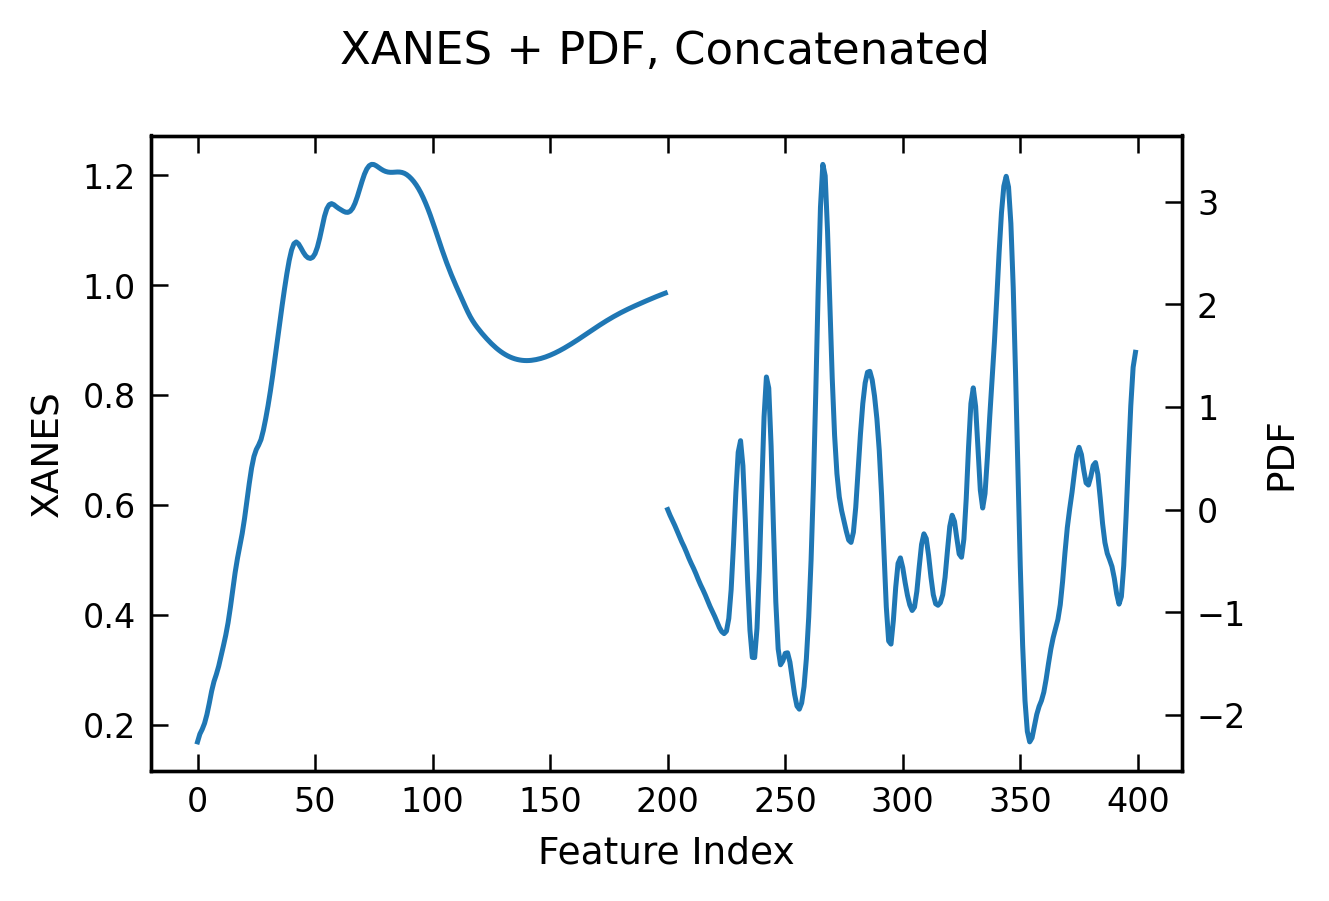

In [13]:
f, ax = plt.subplots(1,1)
ax_twinx = ax.twinx()

ax.plot(np.arange(200), ss.xanes_pdf_pointwise_features[0][:200])
ax_twinx.plot(np.arange(200,400), ss.xanes_pdf_pointwise_features[0][200:])

ax.set_xlabel('Feature Index')
ax.set_ylabel('XANES')
ax_twinx.set_ylabel('PDF')

f.suptitle('XANES + PDF, Concatenated')


Initialize hyperparameter grids for cross-validation with `sklearn.model_selection.GridSearchCV`

In [20]:
ridge_kwargs = {'estimator':Ridge(), 
                             'param_grid': {'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                                           'fit_intercept':[True], 
                            }, 'refit':True, 
                             'metric':mean_squared_error}
                             
                             
lasso_kwargs = {'estimator':Lasso(), 
                'param_grid':{'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                            'fit_intercept':[True]
                    },
                'refit':True,
                'metric':mean_squared_error}

en_kwargs = {'estimator':ElasticNet(), 
                'param_grid':{'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                            'l1_ratio': [0.1, 0.5, 0.9],
                            'fit_intercept':[True]
                            },
                'refit':True,
                'metric':mean_squared_error}

RF_kwargs = {'estimator':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[50,100,200, 300], 
                                        'criterion':['squared_error'],
                                        'max_depth': [10,35, None]},
                'refit':True,
                'metric':mean_squared_error}

RF_kwargs = {'estimator':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[300], 
                                        'criterion':['squared_error'],
                                        'max_depth': [50, None]},
                'refit':True,
                'metric':mean_squared_error}

lcen_kwargs = {'l1_ratio':[0.01,0.1, 0.3, 0.5, 0.6, 0.99],
               'K_fold':5, 
               'cv_method':'Kfold', 
               'alpha':5, 
               'degree':[1],
               'trans_type':'poly', 
               'LCEN_cutoff':5e-2, 
               'LCEN_interaction':True, 
               'scale_X':True, 
               'scale_y':True}

fused_kwargs = {'estimator':FusedLasso(),
    'param_grid':{'alpha':[0.006, 0.008, 0.009, 0.01, 0.015, 0.02, 0.05, 0.1,0.2,0.5,0.9],
                            'fit_intercept':[True]
                    },
                'refit':True,
                'metric':mean_squared_error
}

Additionally, we use the SPA module to perform further nonlinear transformations of the XANES data such as sqrt and polynomial transformations. 

In [15]:
ss.transform_feature('xanes_pointwise_features', degree=2, interaction=False)

#### Model Training 
We set up the pipeline and do all of the training for the different features we created for both the XANES and PDF functions. We train both Random Forest and LCEN models. Each model and feature pair goes through hyperparameter tuning using `sklearn.model_selection.GridSearchCV`

In [21]:
feats = {'pointwise_features':[{'specname':'xanes', 'xrange':ss.xanes_xaxis},
                               {'specname':'pdf', 'xrange':ss.pdf_xaxis}],
         'polynomial_featuresall':[
             { 'specname':'xanes', 'Narr':np.array([4,5,10,20]), 'degree':3},
             { 'specname':'pdf', 'Narr':np.array([4,5,10,20]), 'degree':3}], 
        'cdf': [{ 'specname':'xanes'}],
        'pca': [{ 'specname':'xanes'}, {'specname':'pdf'}],
        'featureagg': [{ 'specname':'xanes'}, {'specname':'pdf'}],
        'pointwise_features_trans' : [{'specname':'xanes'}]
         }
         
sk_kwargs = [RF_kwargs, fused_kwargs]
multi_modal = [('xanes_pointwise_features', 'pdf_pointwise_features'), 
               ('xanes_polynomial_featuresall', 'pdf_polynomial_featuresall')]

ss.do_all(feats, 'nn', 0.20, sk_kwargs=sk_kwargs, lcen_kwargs=lcen_kwargs, 
                multi_modal=multi_modal)

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.0433 | Mean relative error = 0.0144
Test set : RMSE = 0.0390 | Mean relative error = 0.0130
already fitted
already fitted
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.0557 | Mean relative error = 0.0189
Test set : RMSE = 0.0546 | Mean relative error = 0.0199
already fitted
already fitted
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 36 hyperparameter combinations
Completed

#### Benchmarking + Summarizing Performance 
Using simple heatmaps, we quickly visualize the performance of different model and feature pairs by comparing the RMSEs. We go through different statistics to compare to previous studies. 

In [23]:
import seaborn as sns

([<matplotlib.axis.XTick at 0x3ce2d89e0>,
 [Text(0.5, 0, 'RF'), Text(1.5, 0, 'LCEN'), Text(2.5, 0, 'Fused Lasso')])

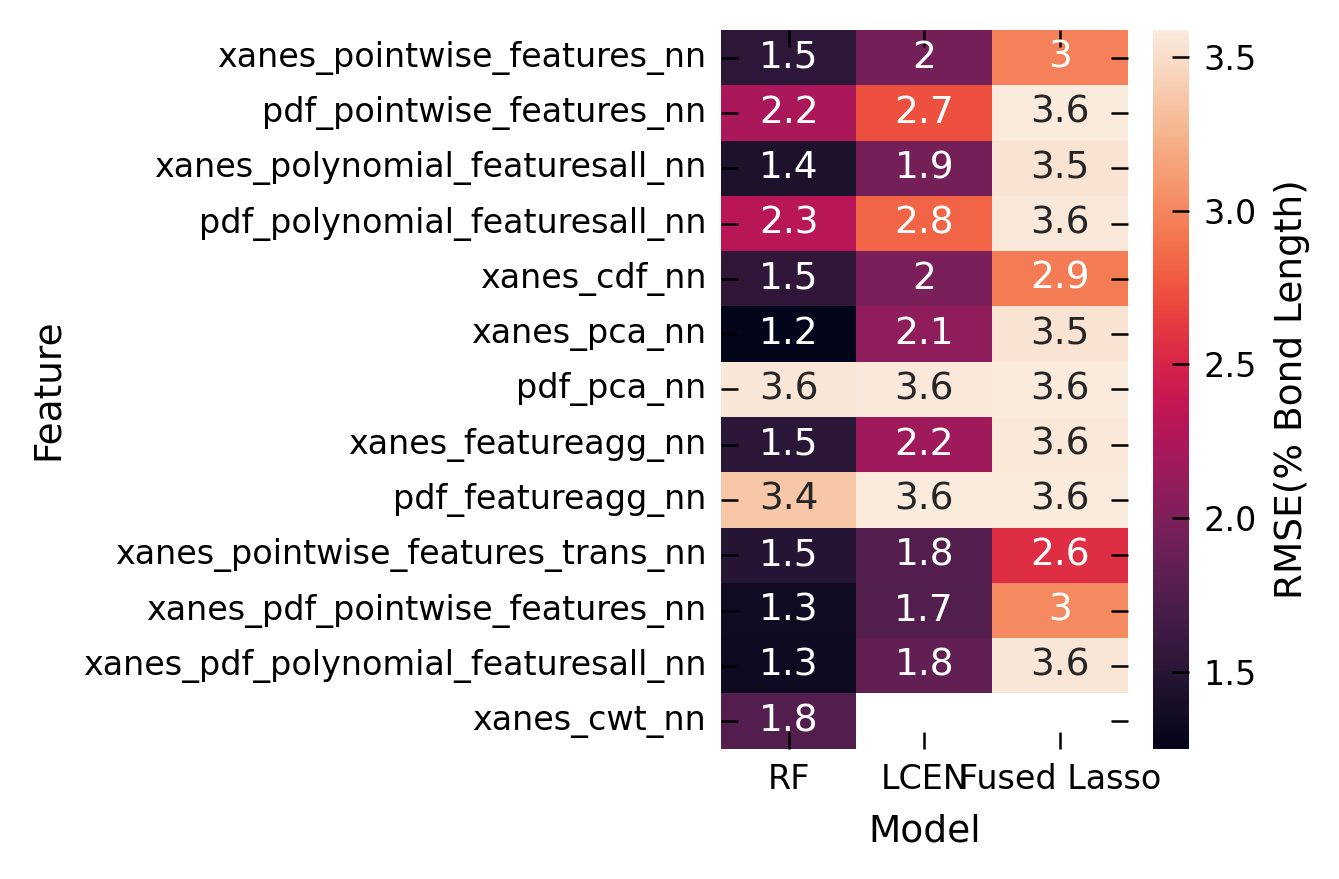

In [221]:
fontsize = 22
ticklabelsize = 18

results_df = np.sqrt(pd.DataFrame(ss.best_fits))[['RandomForestRegressor', 'LCEN', 'FusedLasso']] # best fits given in MSE 
results_df = results_df/np.mean(ss.nn) * 100
sns.heatmap(results_df[['RandomForestRegressor', 'LCEN', 'FusedLasso']], annot=True) #% mean bond length 

plt.xlabel("Model")
plt.ylabel("Feature")
plt.gcf().axes[-1].set_ylabel("RMSE(% Bond Length)")
plt.xticks([0.5,1.5, 2.5], labels=['RF','LCEN', 'Fused Lasso'], ha='center')


In [29]:
xanes_color = '#2176ff'
pdf_color = '#d8315b'
pdf_important_color = '#800016'
xanes_important_color = '#001242'

Minimum RMSE: 0.0249, with feature: xanes_pca_nn, and model : RandomForestRegressor
Maximum RMSE: 0.0715, with feature: pdf_featureagg_nn, and model : LCEN


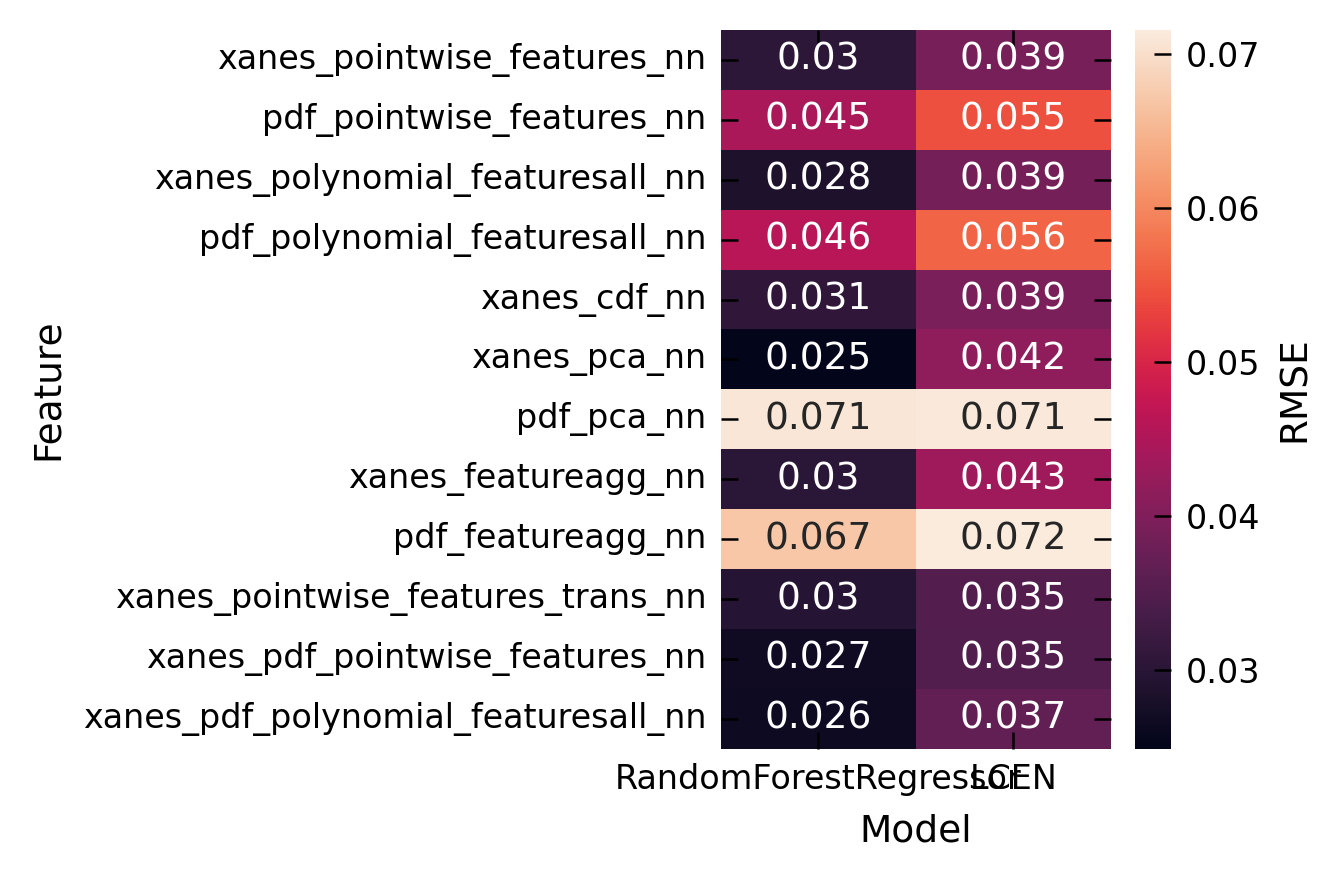

In [30]:
temp_df = np.sqrt(pd.DataFrame(ss.best_fits))[['RandomForestRegressor', 'LCEN']]

sns.heatmap(temp_df[['RandomForestRegressor', 'LCEN']], annot=True)
plt.xlabel("Model")
plt.ylabel("Feature")
plt.gcf().axes[-1].set_ylabel("RMSE")
rmse_min = temp_df[['RandomForestRegressor', 'LCEN']].values.min()
rmse_max = temp_df[['RandomForestRegressor', 'LCEN']].values.max()


# Get the position of min value
min_coords = np.unravel_index(temp_df.values.argmin(), temp_df.shape) 
max_coords = np.unravel_index(temp_df.values.argmax(), temp_df.shape)
min_feat, min_col = temp_df.index[min_coords[0]], temp_df.columns[min_coords[1]]
max_feat, max_col = temp_df.index[max_coords[0]], temp_df.columns[max_coords[1]]

print(f"Minimum RMSE: {rmse_min:.4f}, with feature: {min_feat}, and model : {min_col}")
print(f"Maximum RMSE: {rmse_max:.4f}, with feature: {max_feat}, and model : {max_col}")




Correlation Analysis using Pearson's Correlation & Mutual Information

In [308]:
corr = ss.pearson_feature_selection('nn', ss.generated_features, return_vals=True, k=len(ss.generated_features))
corr_df = pd.DataFrame({'r':[np.abs(corr[key]).mean() for key in corr]}, index=[key for key in corr])

mif = ss.mutual_info_feature_selection('nn', ss.generated_features, return_vals=True, k=len(ss.generated_features))
mif_df = pd.DataFrame({'MIF':[np.abs(mif[key]).mean() for key in mif]}, index=[key for key in mif])

merged = corr_df.merge(mif_df, left_index=True, right_index=True)
merged.to_csv('../JOSS/Figures/XANES_corr.csv')

100%|██████████| 14/14 [00:05<00:00,  2.57it/s]


In [283]:
temp = pd.DataFrame(results_df.T['RandomForestRegressor'])
temp = temp.rename(index = lambda x : x.replace('_nn', ''))

merged_err = merged.join(temp, how='inner')
merged_err.columns = ['r', 'MIF', '% RMSE']

In [239]:
PRETTY_LABELS_DICT = {
        'xanes_pointwise_features':'XANES, Intensity', 'pdf_pointwise_features':'PDF, Intensity',
        'xanes_polynomial_featuresall': 'XANES, Polynomial', 
        'pdf_polynomial_featuresall':'PDF, Polynomial',
        'xanes_cdf':'XANES, CDF', 
        'xanes_pca':'XANES, PCA', 
        'pdf_pca':'PDF, PCA',
        'xanes_featureagg':'XANES, Clustering', 
        'pdf_featureagg': 'PDF, Clustering',
        'xanes_pointwise_features_trans':'XANES, NLTrans', 
        'xanes_pdf_pointwise_features':'XANES + PDF, Intensity', 
        'xanes_pdf_polynomial_featuresall':'XANES + PDF, Polynomial',
        'xanes_cwt': 'XANES, CWT'
}

In [306]:
merged_err = merged_err.rename(PRETTY_LABELS_DICT, axis=0)

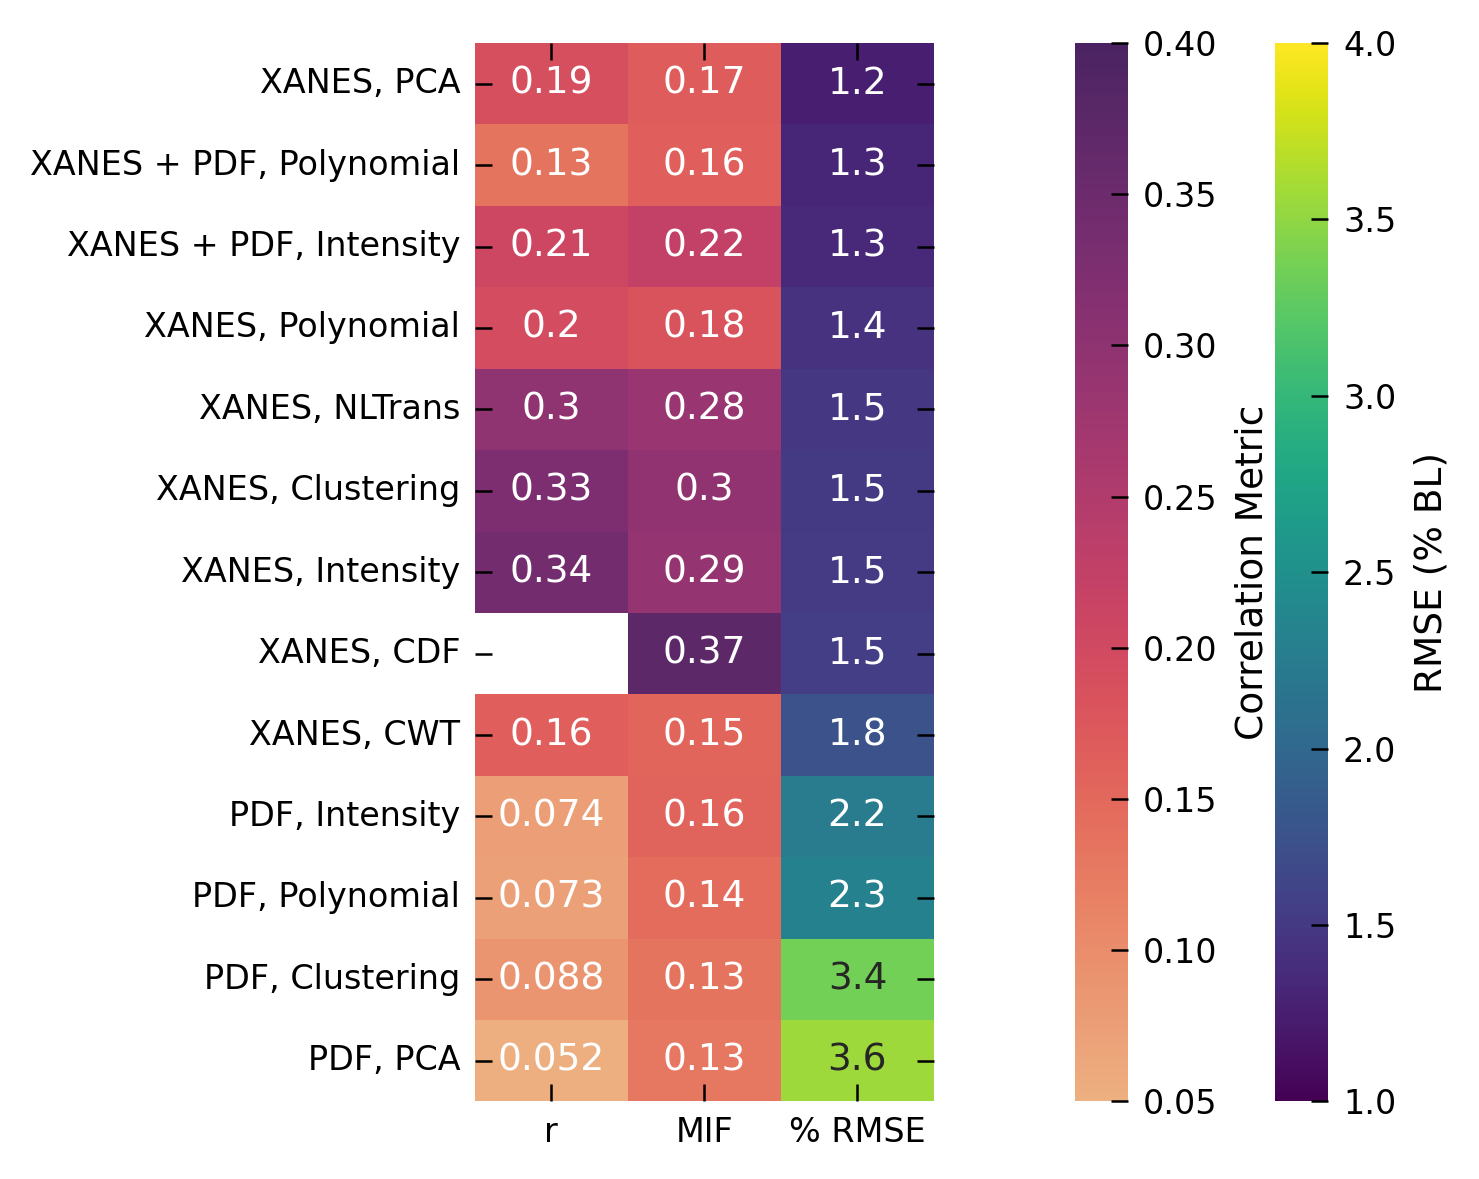

In [307]:
cmap1 = plt.get_cmap('viridis').copy()
cmap1.set_under('none')
cmap2 = plt.get_cmap('flare').copy()
cmap2.set_over('none')
f, ax1 = plt.subplots(1,1,figsize=(5,4))
ax1 = sns.heatmap(merged_err.sort_values('% RMSE'), vmin=1, vmax=4,annot=True, cmap=cmap1, cbar_kws={'pad':0.1})
sns.heatmap(merged_err.sort_values('% RMSE'), vmin=0.05, vmax=0.4, cmap=cmap2, ax=ax1, cbar_kws={'pad':0.2})
# ax1.set_yticklabels([PRETTY_LABELS_DICT[ind] for ind in merged_err.index])

# Add labels to colorbars for the two colorbars present
cbar1 = ax1.collections[0].colorbar
cbar2 = ax1.collections[1].colorbar
cbar1.set_label('RMSE (% BL)')
cbar2.set_label('Correlation Metric')

plt.savefig('/Users/amalyajohnson/Desktop/SpectraScope - 2025/Figures/XANES_Correlation.pdf')
plt.savefig('/Users/amalyajohnson/Desktop/SpectraScope - 2025/Figures/XANES_Correlation.svg')


Various statistics of the different features for benchmarking 

In [121]:
print('min:',results_df.min().min(), 'max:',results_df.max().max())

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error

y_test = ss.nn_test
for feat in ['xanes_pointwise_features_nn', 'xanes_cdf_nn', 'xanes_pca_nn', 'xanes_polynomial_featuresall_nn']:
    print('----------------------------')
    print('feature:', feat)
    mse = ss.best_fits['RandomForestRegressor'][feat]
    y_pred = ss.__getattribute__(feat + '_RandomForestRegressor')['ypred']
    print('mse:',mean_squared_error(y_test, y_pred))
    print('mae:',mean_absolute_error(y_test, y_pred))
    print('R2:',r2_score(y_test, y_pred))
    print('rmse:',root_mean_squared_error(y_test, y_pred))
    print(' % rmse mean bond length:',root_mean_squared_error(y_test, y_pred)/np.mean(ss.nn)*100)

min: 1.2490654544981061 max: 3.5876069171710365
----------------------------
feature: xanes_pointwise_features_nn
mse: 0.0009257495132409228
mae: 0.016899498105781854
R2: 0.8139938378928433
rmse: 0.030426132078213996
 % rmse mean bond length: 1.5248763401511638
----------------------------
feature: xanes_cdf_nn
mse: 0.0009561510264334079
mae: 0.017524668008551608
R2: 0.8078854157869678
rmse: 0.030921691842999276
 % rmse mean bond length: 1.549712469781753
----------------------------
feature: xanes_pca_nn
mse: 0.0006211473472159527
mae: 0.015024206273884889
R2: 0.8751960087408518
rmse: 0.024922827833453263
 % rmse mean bond length: 1.2490654544981061
----------------------------
feature: xanes_polynomial_featuresall_nn
mse: 0.0008092548287525136
mae: 0.01712003101226059
R2: 0.8374005249692575
rmse: 0.028447404604858305
 % rmse mean bond length: 1.4257078129137608


Utility functions for help plotting

In [178]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image
from spectrascope.Features import SpectralFeatures
import os
import string


def load_and_resize_image(img_path, max_size=128):
    """
    Load an image from the given path and resize it so that its largest dimension
    (width or height) does not exceed `max_size`, while maintaining the aspect ratio.

    Parameters
    ----------
    img_path : str
        Path to the image file to be loaded and resized.
    max_size : int, optional
        Maximum allowed size for the width or height of the image (default is 128).

    Returns
    -------
    np.ndarray
        The resized image as a NumPy array.
    """
    im = Image.open(img_path)
    w, h = im.size
    scale = min(max_size / w, max_size / h, 1.0)
    new_size = (int(w * scale), int(h * scale))
    im_resized = im.resize(new_size, resample=Image.LANCZOS)
    return np.asarray(im_resized)

def plot_spectral_features_matplotlib(xaxis, raw, selected_features, ax=None,zoom=0.1,
                                      plot_raw=True, plot=True, resize=True):
    """
    Plots spectral features on a matplotlib axis, overlaying polynomial feature images at selected feature locations.

    Parameters
    ----------
    xaxis : array-like
        The x-axis values of the spectrum.
    raw : array-like
        The raw spectrum values.
    selected_features : list or array-like
        Indices of selected features to highlight.
    ax : matplotlib.axes.Axes, optional
        The axis to plot on. If None, a new figure and axis are created.
    zoom : float, default=0.1
        Zoom factor for the overlaid images.
    plot_raw : bool, default=True
        Whether to plot the raw spectrum.
    plot : bool, default=True
        Whether to overlay feature images.
    resize : bool, default=True
        Whether to resize the feature images.

    Returns
    -------
    ax : matplotlib.axes.Axes
        The axis with the plot.
    centers : list
        List of x-axis positions where features/images were overlaid.

    Notes
    -----
    This function uses polynomial feature images (const, line, par, cubic) and overlays them at the
    corresponding feature locations on the spectrum. The images should be located in '../app/static/'.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    
    # Plot the raw spectrum
    if plot_raw:
        ax.plot(xaxis, raw, color='black', lw=1)

    # Generate binned features
    temp = SpectralFeatures(xaxis, raw)
    for bins in [4, 5, 10, 20]:
        temp.generate_bins(bins)

    # Feature ID config
    feature_config = [
        (0, 16,  'bin_indices_4',  'const', 4),
        (16, 36, 'bin_indices_5',  'line',  5),
        (36, 76, 'bin_indices_10', 'par',   10),
        (76, 156, 'bin_indices_20', 'cubic', 20),
    ]

    def find_nearest(array, value):
        return np.abs(array - value).argmin()

    centers = []
    for selected_id in selected_features:
        for id_min, id_max, bin_label, poly_label, num_bins in feature_config:
            if id_min <= selected_id < id_max:
                search_bins = np.linspace(id_min, id_max, num_bins)
                located_bin = np.argwhere(selected_id < search_bins)[0][0]
                bin_mask = getattr(temp, bin_label) == located_bin
                center = np.median(xaxis[bin_mask])
                height_id = find_nearest(xaxis, center)
                height = raw[height_id]

                # Load image
                if plot: 
                    img_path = f"../app/static/{poly_label}.png"
                    if not os.path.exists(img_path):
                        print(f"Warning: {img_path} not found.")
                        continue
                    if resize: 
                        im = load_and_resize_image(img_path)
                    else:
                        im = Image.open(img_path)
                    


                    # Convert image to matplotlib offsetbox
                    imagebox = OffsetImage(im, zoom=zoom)
                    ab = AnnotationBbox(imagebox, (center, height), frameon=False)
                    ax.add_artist(ab)
                centers.append((selected_id, center))
                break  # stop after first matching range

    centers = np.array(centers)
    return ax, centers

def plot_ss_summary(ss, results_df,save_path=None, add_label = '', show_importances=False):
    """
    Plots the results for a given element using the provided SpectraScope object and results DataFrame.

    Parameters
    ----------
    ss : SpectraScope
        The SpectraScope object containing the spectral data and methods.
    results_df : pandas.DataFrame
        DataFrame containing the results to visualize. Expected to have model names as columns and featurization schemes as rows.
    save_path : str, optional
        If provided, the path to save the resulting figure.
    add_label : str, optional
        Any other identifier wanted for saving the filename 
    show_importances : bool, default False
        Whether to display feature importances on the plots.

    Returns
    -------
    None
        Displays and/or saves the generated plot.
    """
    xanes_color = '#2176ff'
    pdf_color = '#d8315b'

    pdf_important_color = '#800016'
    xanes_important_color = '#001242'

    fontsize = 25
    ticklabelsize = 20

    pretty_labels = [PRETTY_LABELS_DICT[ind.replace('_nn', '')] for ind in results_df.T.index]

    # --- Figure and axes setup ---
    fig = plt.figure(figsize=(20, 16), constrained_layout=True)
    gs = gridspec.GridSpec(2, 4, figure=fig, width_ratios=[1.2, 2, 2, 2])
    ax1 = fig.add_subplot(gs[:, 0])
    ax2 = fig.add_subplot(gs[0, 2])
    ax3 = fig.add_subplot(gs[0, 3])
    ax4 = fig.add_subplot(gs[1, 2:])
    ax5 = fig.add_subplot(gs[0, 1])
    ax6 = fig.add_subplot(gs[1, 1])

    # --- Results heatmap ---
    im = ax1.imshow(results_df.T, cmap='plasma')
    ax1.set_yticks(np.arange(len(pretty_labels)))
    ax1.set_yticklabels(pretty_labels, rotation=45, ha='right')
    ax1.set_xticks([0, 1])
    ax1.set_xticklabels(['RF', 'LCEN'])
    cb1 = fig.colorbar(im, ax=ax1, location='top', aspect=5, pad=0.01)
    cb1.ax.tick_params(labelsize=ticklabelsize)
    cb1.set_label('% BL', fontsize=fontsize)

    # Annotate heatmap with values
    for (i, j), val in np.ndenumerate(results_df.T):
        ax1.text(j, i, f'{val:.3f}', ha='center', va='center', color='white', size=ticklabelsize)

    # Highlight top 3 results
    rows = [0, 0, 0]
    cols = np.argsort(results_df.T['RandomForestRegressor'].values)[:3]
    colors = ['green', 'dodgerblue', 'crimson']
    for r, c, color in zip(rows, cols, colors):
        ax1.plot(r, c - 0.3, color=color, marker='*', markersize=20)

    # --- PCA scatter plot ---
    top_pca = ss.xanes_pca_nn_RandomForestRegressor['selected_features'][:2]
    ax6.scatter(
        ss.xanes_pca[:, top_pca[0]],
        ss.xanes_pca[:, top_pca[1]],
        c=ss.nn, cmap='viridis',
        s=40
    )

    # --- XANES and PDF mean spectra ---
    mean_xanes = np.mean(ss.xanes_pointwise_features, axis=0)
    mean_pdf = np.mean(ss.pdf_pointwise_features, axis=0)

    for xane_spec in ss.xanes_pointwise_features:
        ax2.plot(ss.xanes_xaxis, xane_spec, color=xanes_color, alpha=0.01)
    for pdf_spec in ss.pdf_pointwise_features:
        ax3.plot(ss.pdf_xaxis, pdf_spec, color=pdf_color, alpha=0.01)

    ax2.plot(ss.xanes_xaxis, mean_xanes, color='black', linewidth=2)
    ax3.plot(ss.pdf_xaxis, mean_pdf, color='black', linewidth=2)

    # --- XANES CDF plot ---
    ax5.plot(ss.xanes_xaxis, mean_xanes, color='black', linewidth=2)
    ax5_twin = ax5.twinx()
    for xane_spec in ss.xanes_cdf:
        ax5_twin.plot(ss.xanes_xaxis, xane_spec, color=xanes_color, alpha=0.01)

    # --- Highlight top XANES CDF features ---
    top_xanes_cdf_ids = ss.xanes_cdf_nn_RandomForestRegressor['selected_features']
    for idx in top_xanes_cdf_ids[:3]:
        ax5.vlines(
            ss.xanes_xaxis[idx], ymin=-0.1, ymax=1.5,
            linewidth=1.5, colors=xanes_important_color, linestyles='dashed'
        )

    # --- Plot feature images and get feature centers ---
    _, xanes_centers = plot_spectral_features_matplotlib(
        ss.xanes_xaxis, mean_xanes,
        ss.xanes_polynomial_featuresall_nn_RandomForestRegressor['selected_features'][:10],
        zoom=0.07, ax=ax2, plot_raw=False, resize=False
    )
    _, pdf_centers = plot_spectral_features_matplotlib(
        ss.pdf_xaxis, mean_pdf,
        ss.pdf_polynomial_featuresall_nn_RandomForestRegressor['selected_features'][:10],
        zoom=0.07, ax=ax3, plot_raw=False, resize=False
    )

    # --- XANES + PDF polynomial features ---
    full_important = ss.xanes_pdf_polynomial_featuresall_nn_RandomForestRegressor['P'].feature_importances_
    full_x = np.arange(len(ss.xanes_xaxis) + len(ss.pdf_xaxis))
    full_y = np.concatenate((mean_xanes, mean_pdf))
    _, full_centers = plot_spectral_features_matplotlib(
        full_x, full_y,
        ss.xanes_pdf_polynomial_featuresall_nn_RandomForestRegressor['selected_features'],
        zoom=0.07, ax=ax4, plot_raw=True, plot=True, resize=False
    )

    # --- Twin axes for importances ---
    ax2_twin = ax2.twinx()
    ax3_twin = ax3.twinx()
    ax4_twin = ax4.twinx()

    if show_importances:
        ax2_twin.plot(
            ss.xanes_xaxis,
            ss.xanes_pointwise_features_nn_RandomForestRegressor['P'].feature_importances_,
            color='k'
        )
        ax3_twin.plot(
            ss.pdf_xaxis,
            ss.pdf_pointwise_features_nn_RandomForestRegressor['P'].feature_importances_,
            color='k'
        )
        ax4_twin.plot(
            ss.xanes_pdf_pointwise_features_nn_RandomForestRegressor['P'].feature_importances_,
            color='k'
        )

    # --- Highlight top XANES and PDF polynomial features ---
    top_xanes_ids = ss.xanes_polynomial_featuresall_nn_RandomForestRegressor['selected_features']
    for i, _ in enumerate(top_xanes_ids[:3]):
        center = xanes_centers[i][1]
        nearest = find_nearest(center, ss.xanes_xaxis)
        if not show_importances:
            ax2.vlines(
                center, ymin=-0.1, ymax=2.5,
                linewidth=1.5, colors=xanes_important_color, linestyles='dashed'
            )
            ax2_twin.set_yticks([])
            ax4_twin.set_yticks([])
        ax4.vlines(
            nearest, ymin=-2, ymax=2,
            linewidth=1.5, colors=xanes_important_color, linestyles='dashed'
        )

    top_pdf_ids = ss.pdf_polynomial_featuresall_nn_RandomForestRegressor['selected_features']
    for i, _ in enumerate(top_pdf_ids[:3]):
        center = pdf_centers[i][1]
        nearest = find_nearest(center, ss.pdf_xaxis)
        if not show_importances:
            ax3.vlines(
                center, ymin=-10, ymax=15,
                linewidth=1.5, colors=pdf_important_color, linestyles='dashed'
            )
            ax3_twin.set_yticks([])
        ax4.vlines(
            200 + nearest, ymin=-2, ymax=2,
            linewidth=1.5, colors=pdf_important_color, linestyles='dashed'
        )

    # --- Plot concatenated XANES+PDF mean spectra ---
    ax4.plot(full_x[:200], full_y[:200], color=xanes_color)
    ax4.plot(full_x[200:], full_y[200:], color=pdf_color)

    # --- Axis labels and limits ---
    if show_importances:
        ax2_twin.set_ylabel('Importance', fontsize=fontsize)
        ax3_twin.set_ylabel('Importance', fontsize=fontsize)
        ax4_twin.set_ylabel('Importance', fontsize=fontsize)

    ax2.set_xlabel('Energy (eV)', fontsize=fontsize)
    ax2.set_ylabel(r'$\mu$ (arb.)', fontsize=fontsize)
    ax5.set_xlabel('Energy (eV)', fontsize=fontsize)
    ax5.set_ylabel(r'$\mu$ (arb.)', fontsize=fontsize)
    ax5_twin.set_ylabel('CDF', fontsize=fontsize)
    ax6.set_xlabel(f'PC {top_pca[0] + 1}', fontsize=fontsize)
    ax6.set_ylabel(f'PC {top_pca[1] + 1}', fontsize=fontsize)
    ax3.set_xlabel(r'r ($\AA$)', fontsize=fontsize)
    ax3.set_ylabel(r'G ($\AA^{-1}$)', fontsize=fontsize)
    ax4.set_xlabel('Feature Index', fontsize=fontsize)
    ax4.set_yticks([])

    # --- Axis limits and titles ---
    ax2.set_ylim(-0.1, 2.5)
    ax3.set_ylim(-10, 15)
    ax4.set_ylim(-2, 2)
    ax2.set_title('XANES, Poly', size=fontsize)
    ax3.set_title('PDF, Poly', size=fontsize)
    ax4.set_title('XANES + PDF, Poly', size=fontsize)
    ax5.set_title('XANES, CDF', size=fontsize)
    ax6.set_title('XANES, PCA', size=fontsize)
    # ax
    for ax in [ax1, ax2, ax2_twin, ax3_twin, ax3, ax4, ax4_twin, ax5, ax6, ax5_twin]:
        ax.tick_params(axis='both', labelsize=ticklabelsize)
        ax.xaxis.label.set_size(fontsize)
        ax.yaxis.label.set_size(fontsize)


    if save_path:
        plt.savefig(f"{save_path}/{add_label}_xanes_pdf_mpl.svg")
        plt.savefig(f"{save_path}/{add_label}_xanes_pdf_mpl.pdf")



#### Figure 3

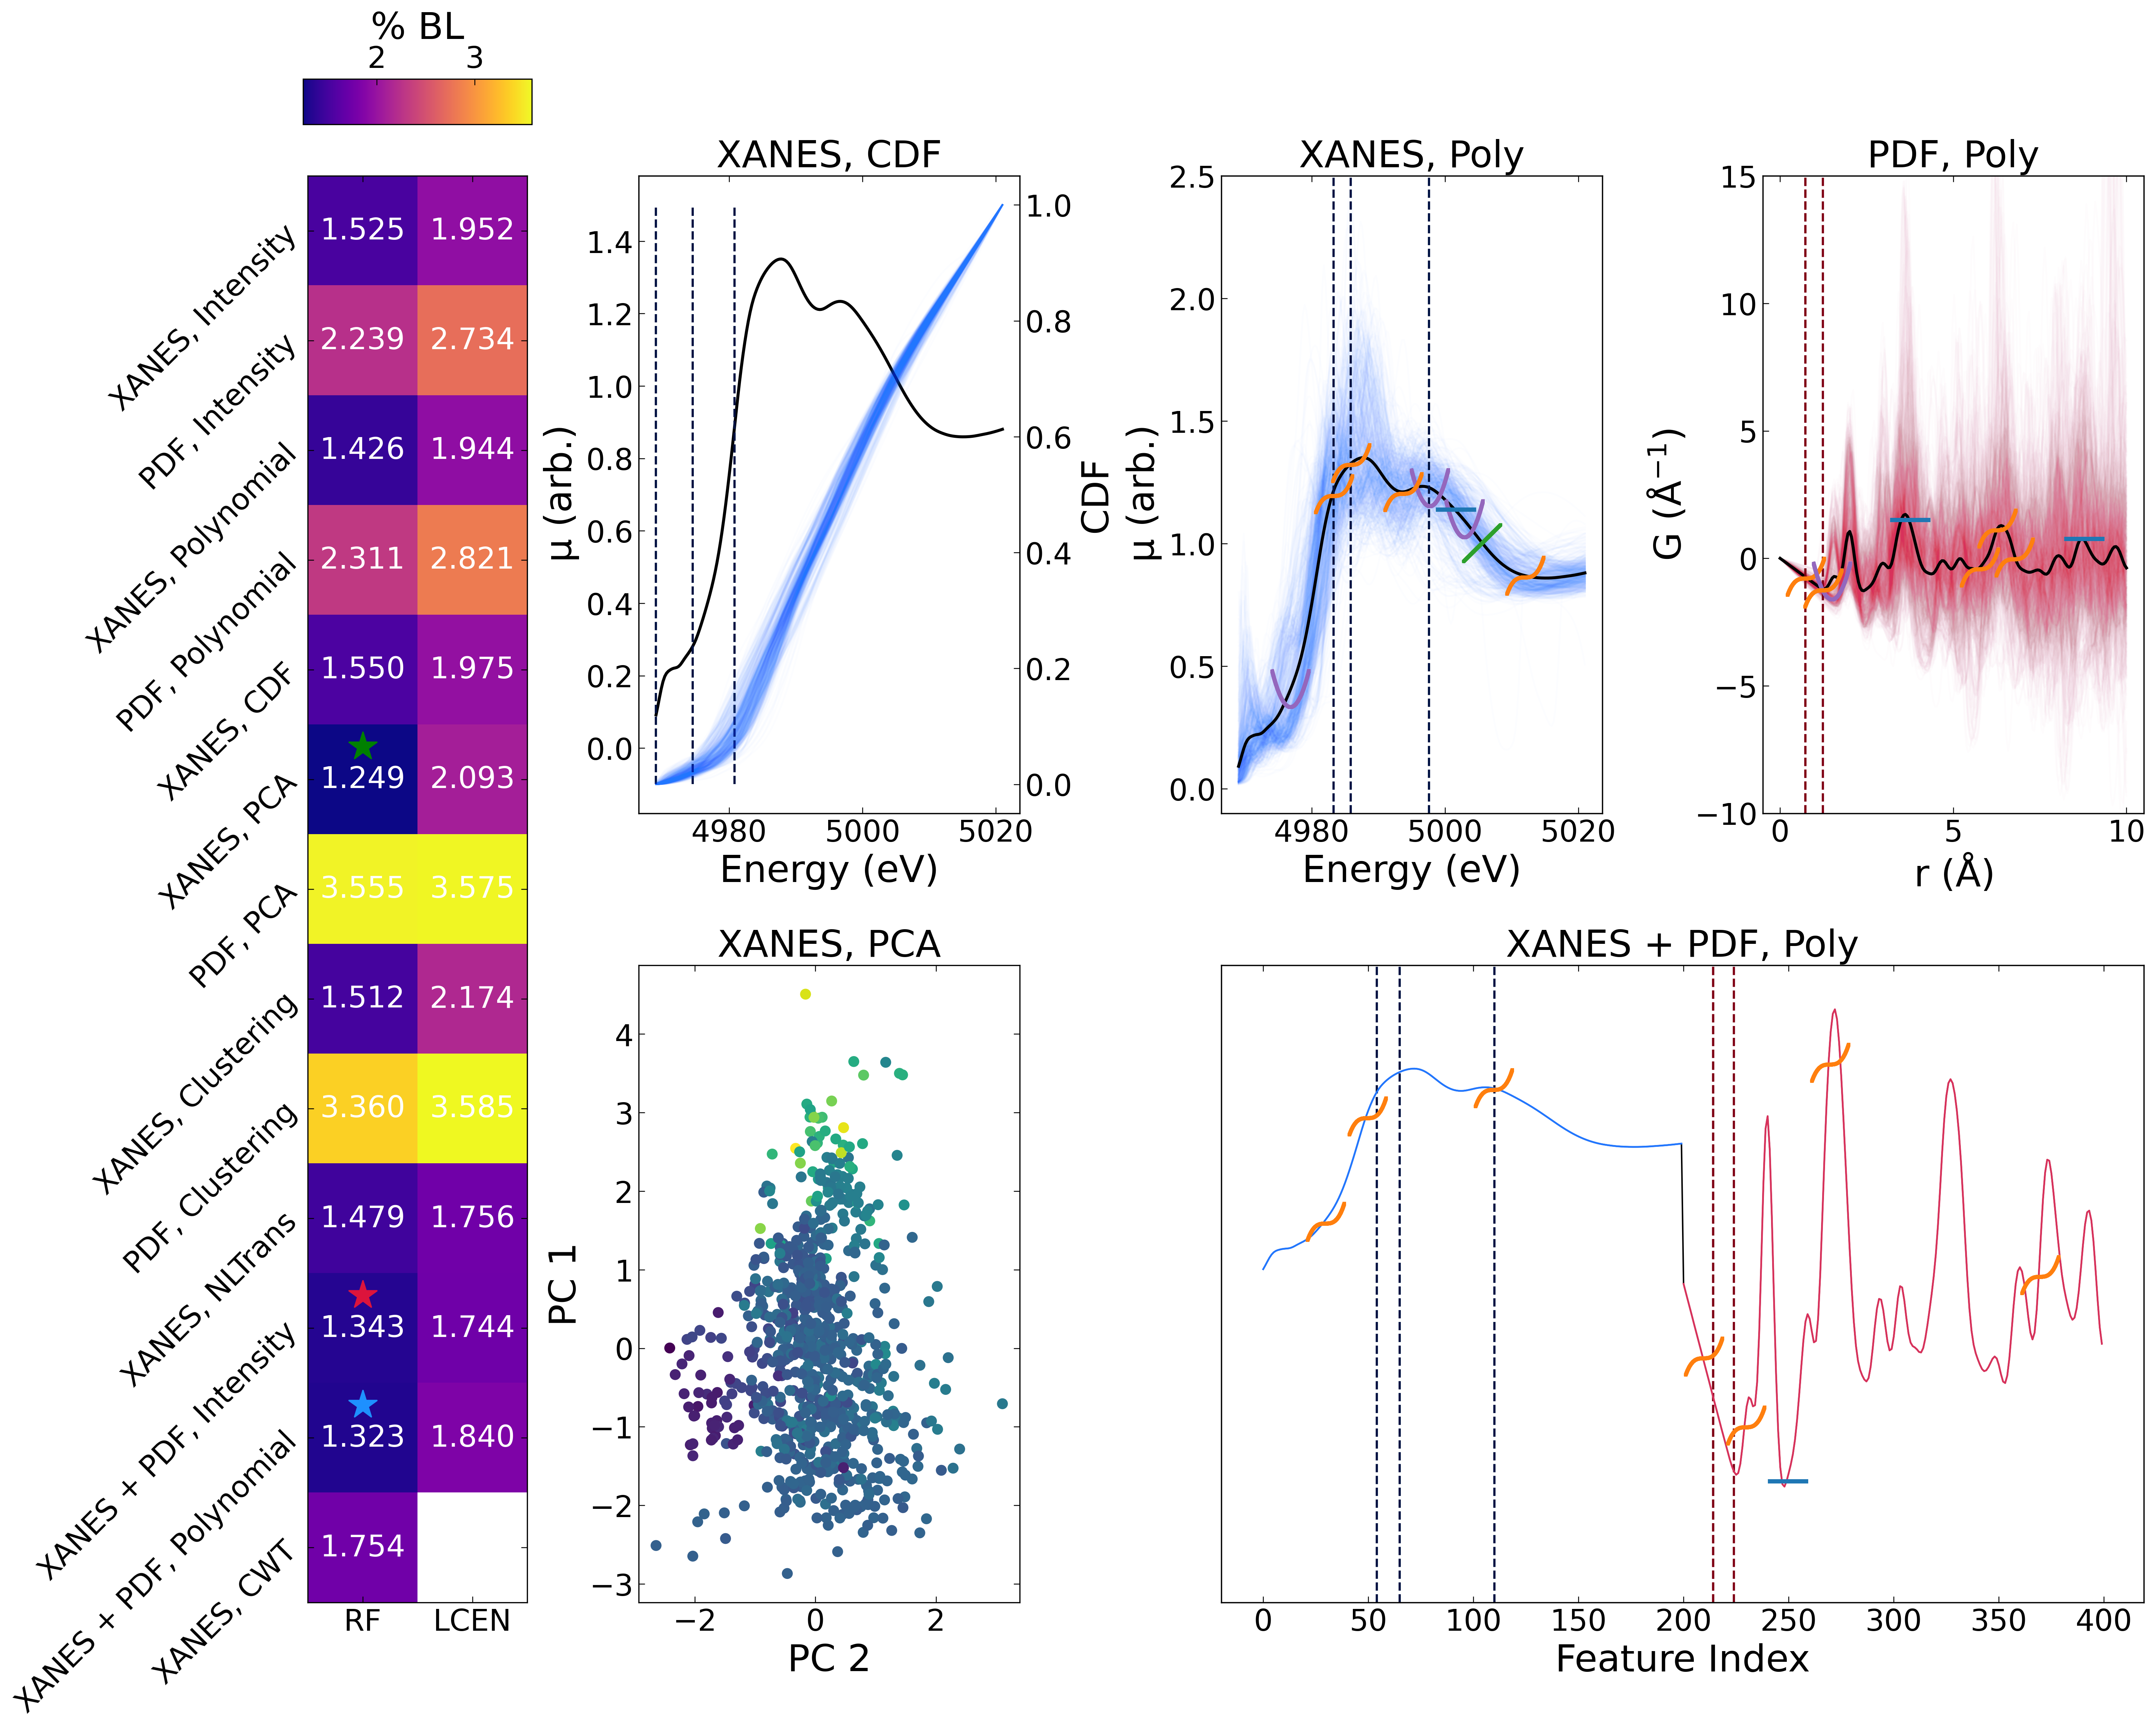

In [262]:
results_df = (np.sqrt(pd.DataFrame(ss.best_fits)[['RandomForestRegressor', 'LCEN']].T) / ss.nn.mean() * 100)
plot_ss_summary(ss,results_df, add_label = 'Ti_Fig3', save_path='/Users/amalyajohnson/Desktop/SpectraScope - 2025/Figures')

#### Supplementary Figures

Text(0.5, 1.0, 'XANES, PCA')

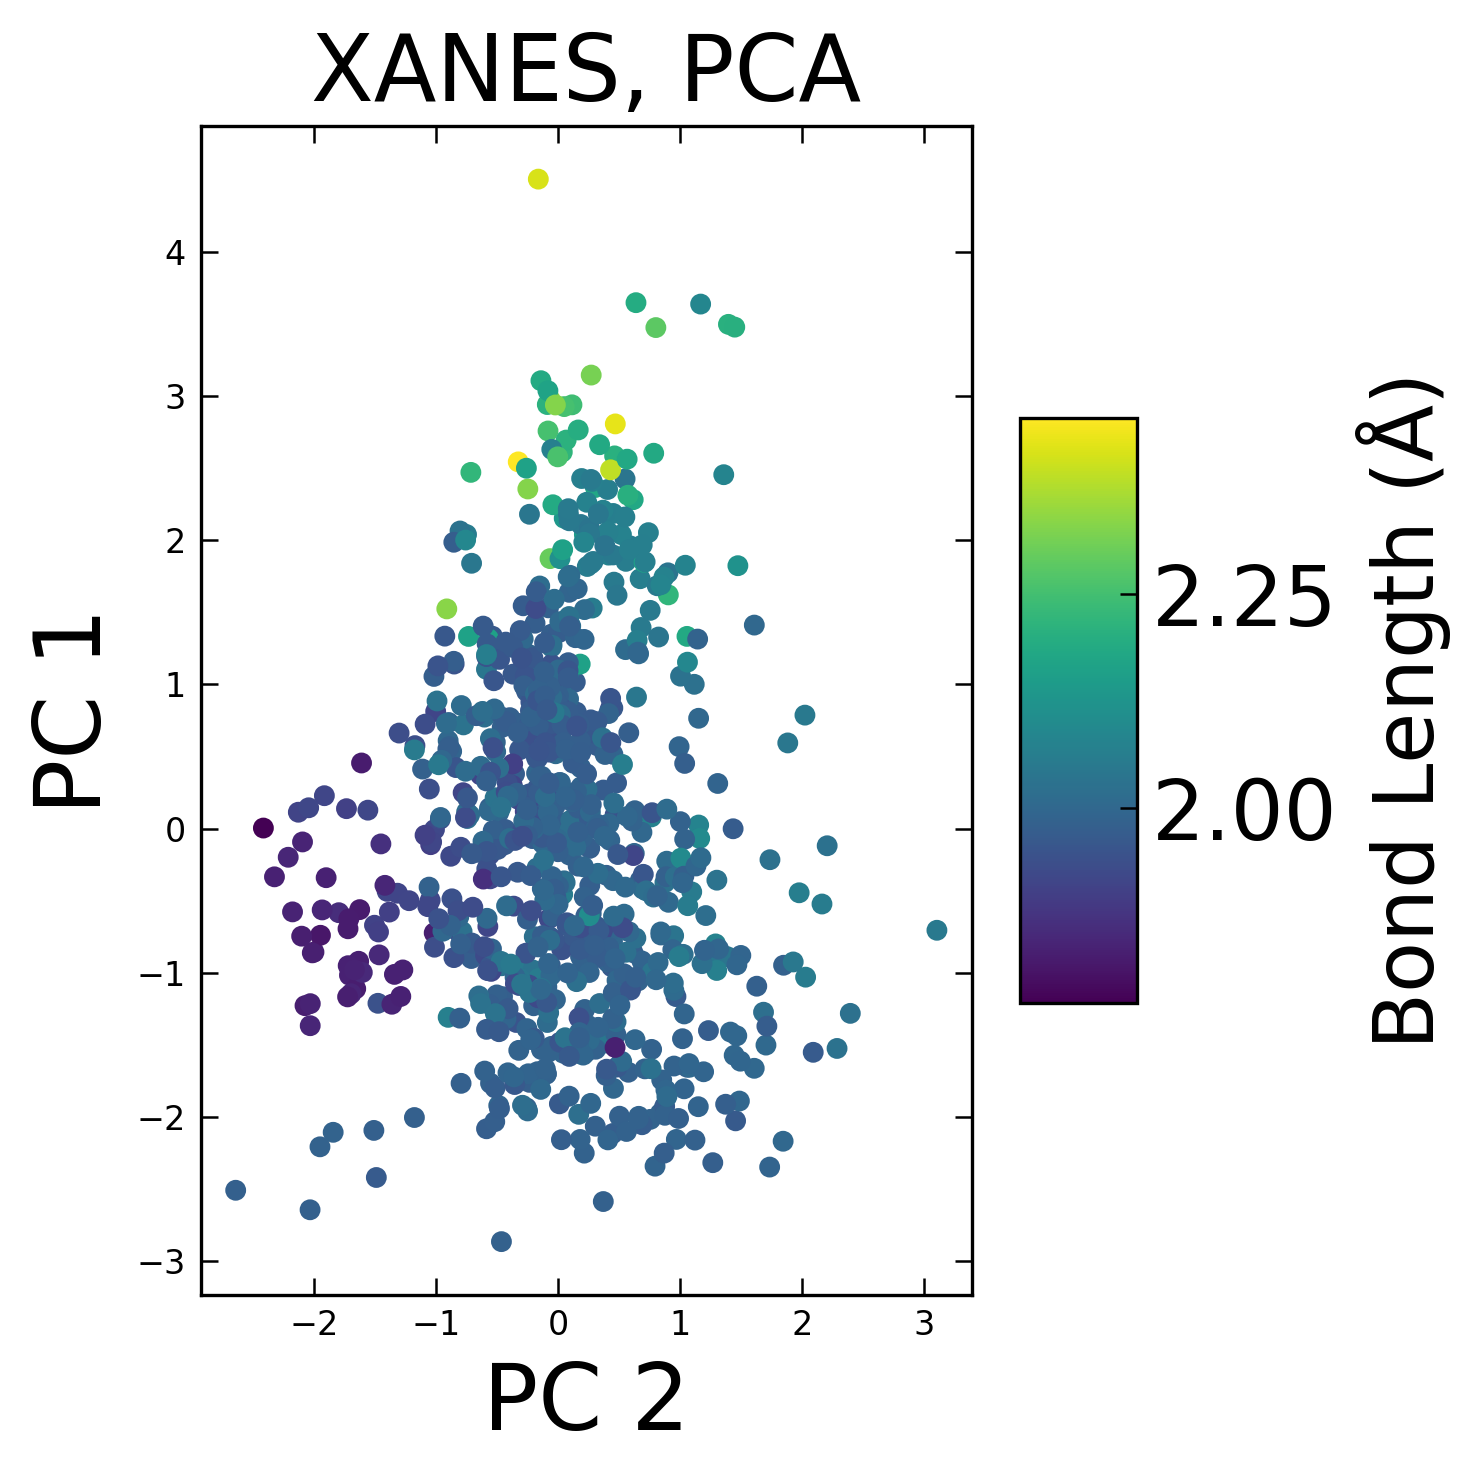

In [139]:
# for getting colorbar for PCA
top_pca = ss.xanes_pca_nn_RandomForestRegressor['selected_features'][:2]
f, ax = plt.subplots(1,1, figsize=(5,5))
scatter = ax.scatter(ss.xanes_pca[:, top_pca[0]], ss.xanes_pca[:, top_pca[1]], c=ss.nn, cmap='viridis')

cbar = plt.colorbar(scatter, aspect=5, shrink=0.5)
cbar.set_label(r'Bond Length $(\AA)$ ',size=20)
cbar.ax.tick_params(labelsize=20)
ax.set_xlabel(f'PC {top_pca[0] + 1}', fontsize=fontsize)
ax.set_ylabel(f'PC {top_pca[1] + 1}', fontsize=fontsize)
ax.set_title('XANES, PCA', size=fontsize)


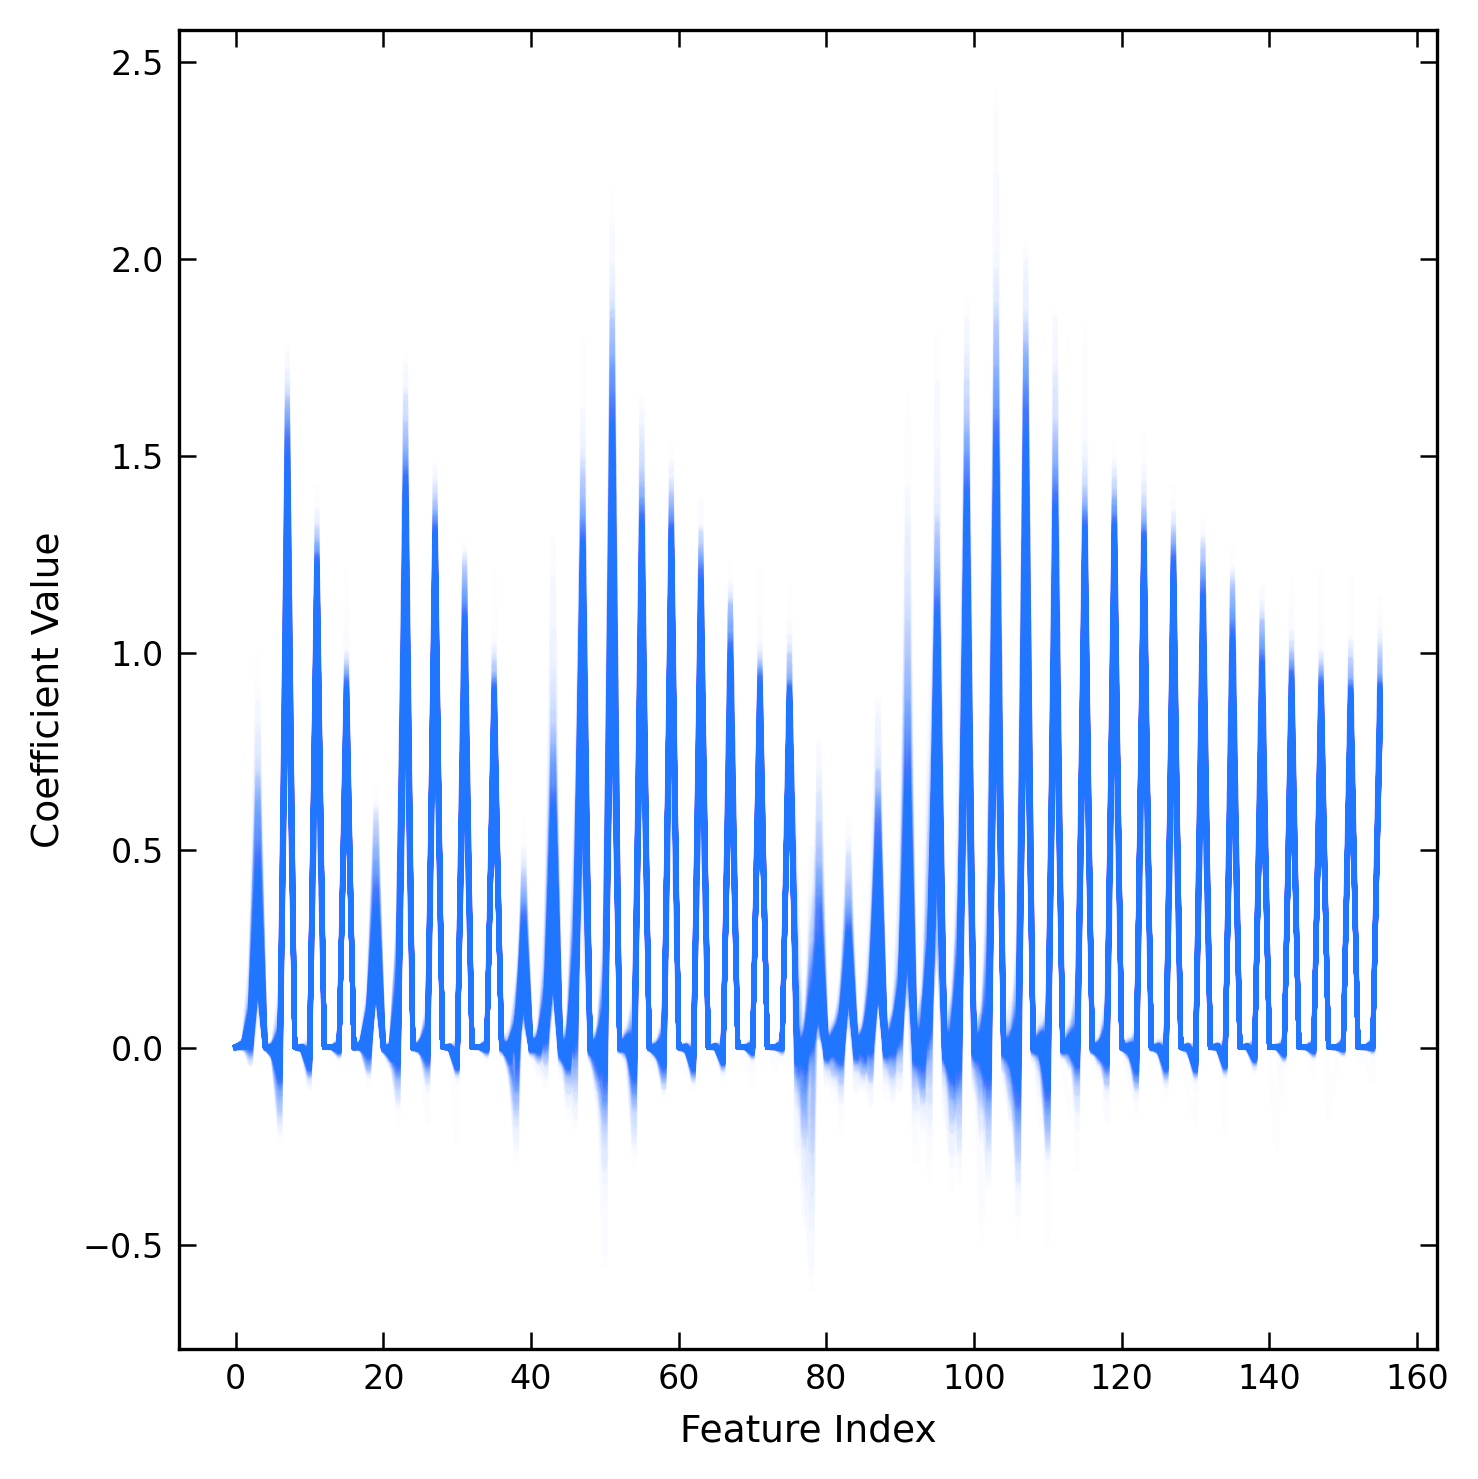

In [140]:
f, (ax1) = plt.subplots(1,1,figsize=(5,5))
xanes_color = '#2176ff'

for spec in ss.xanes_polynomial_featuresall: 
    ax1.plot(np.arange(156), spec[:-1], color=xanes_color, alpha=0.01)
    
ax1.set_xlabel('Feature Index')
ax1.set_ylabel('Coefficient Value')

save_path = None
if save_path:
    plt.savefig(f"{save_path}/supplementary_polycoefs.svg")
    plt.savefig(f"{save_path}/supplementary_polycoefs.pdf")

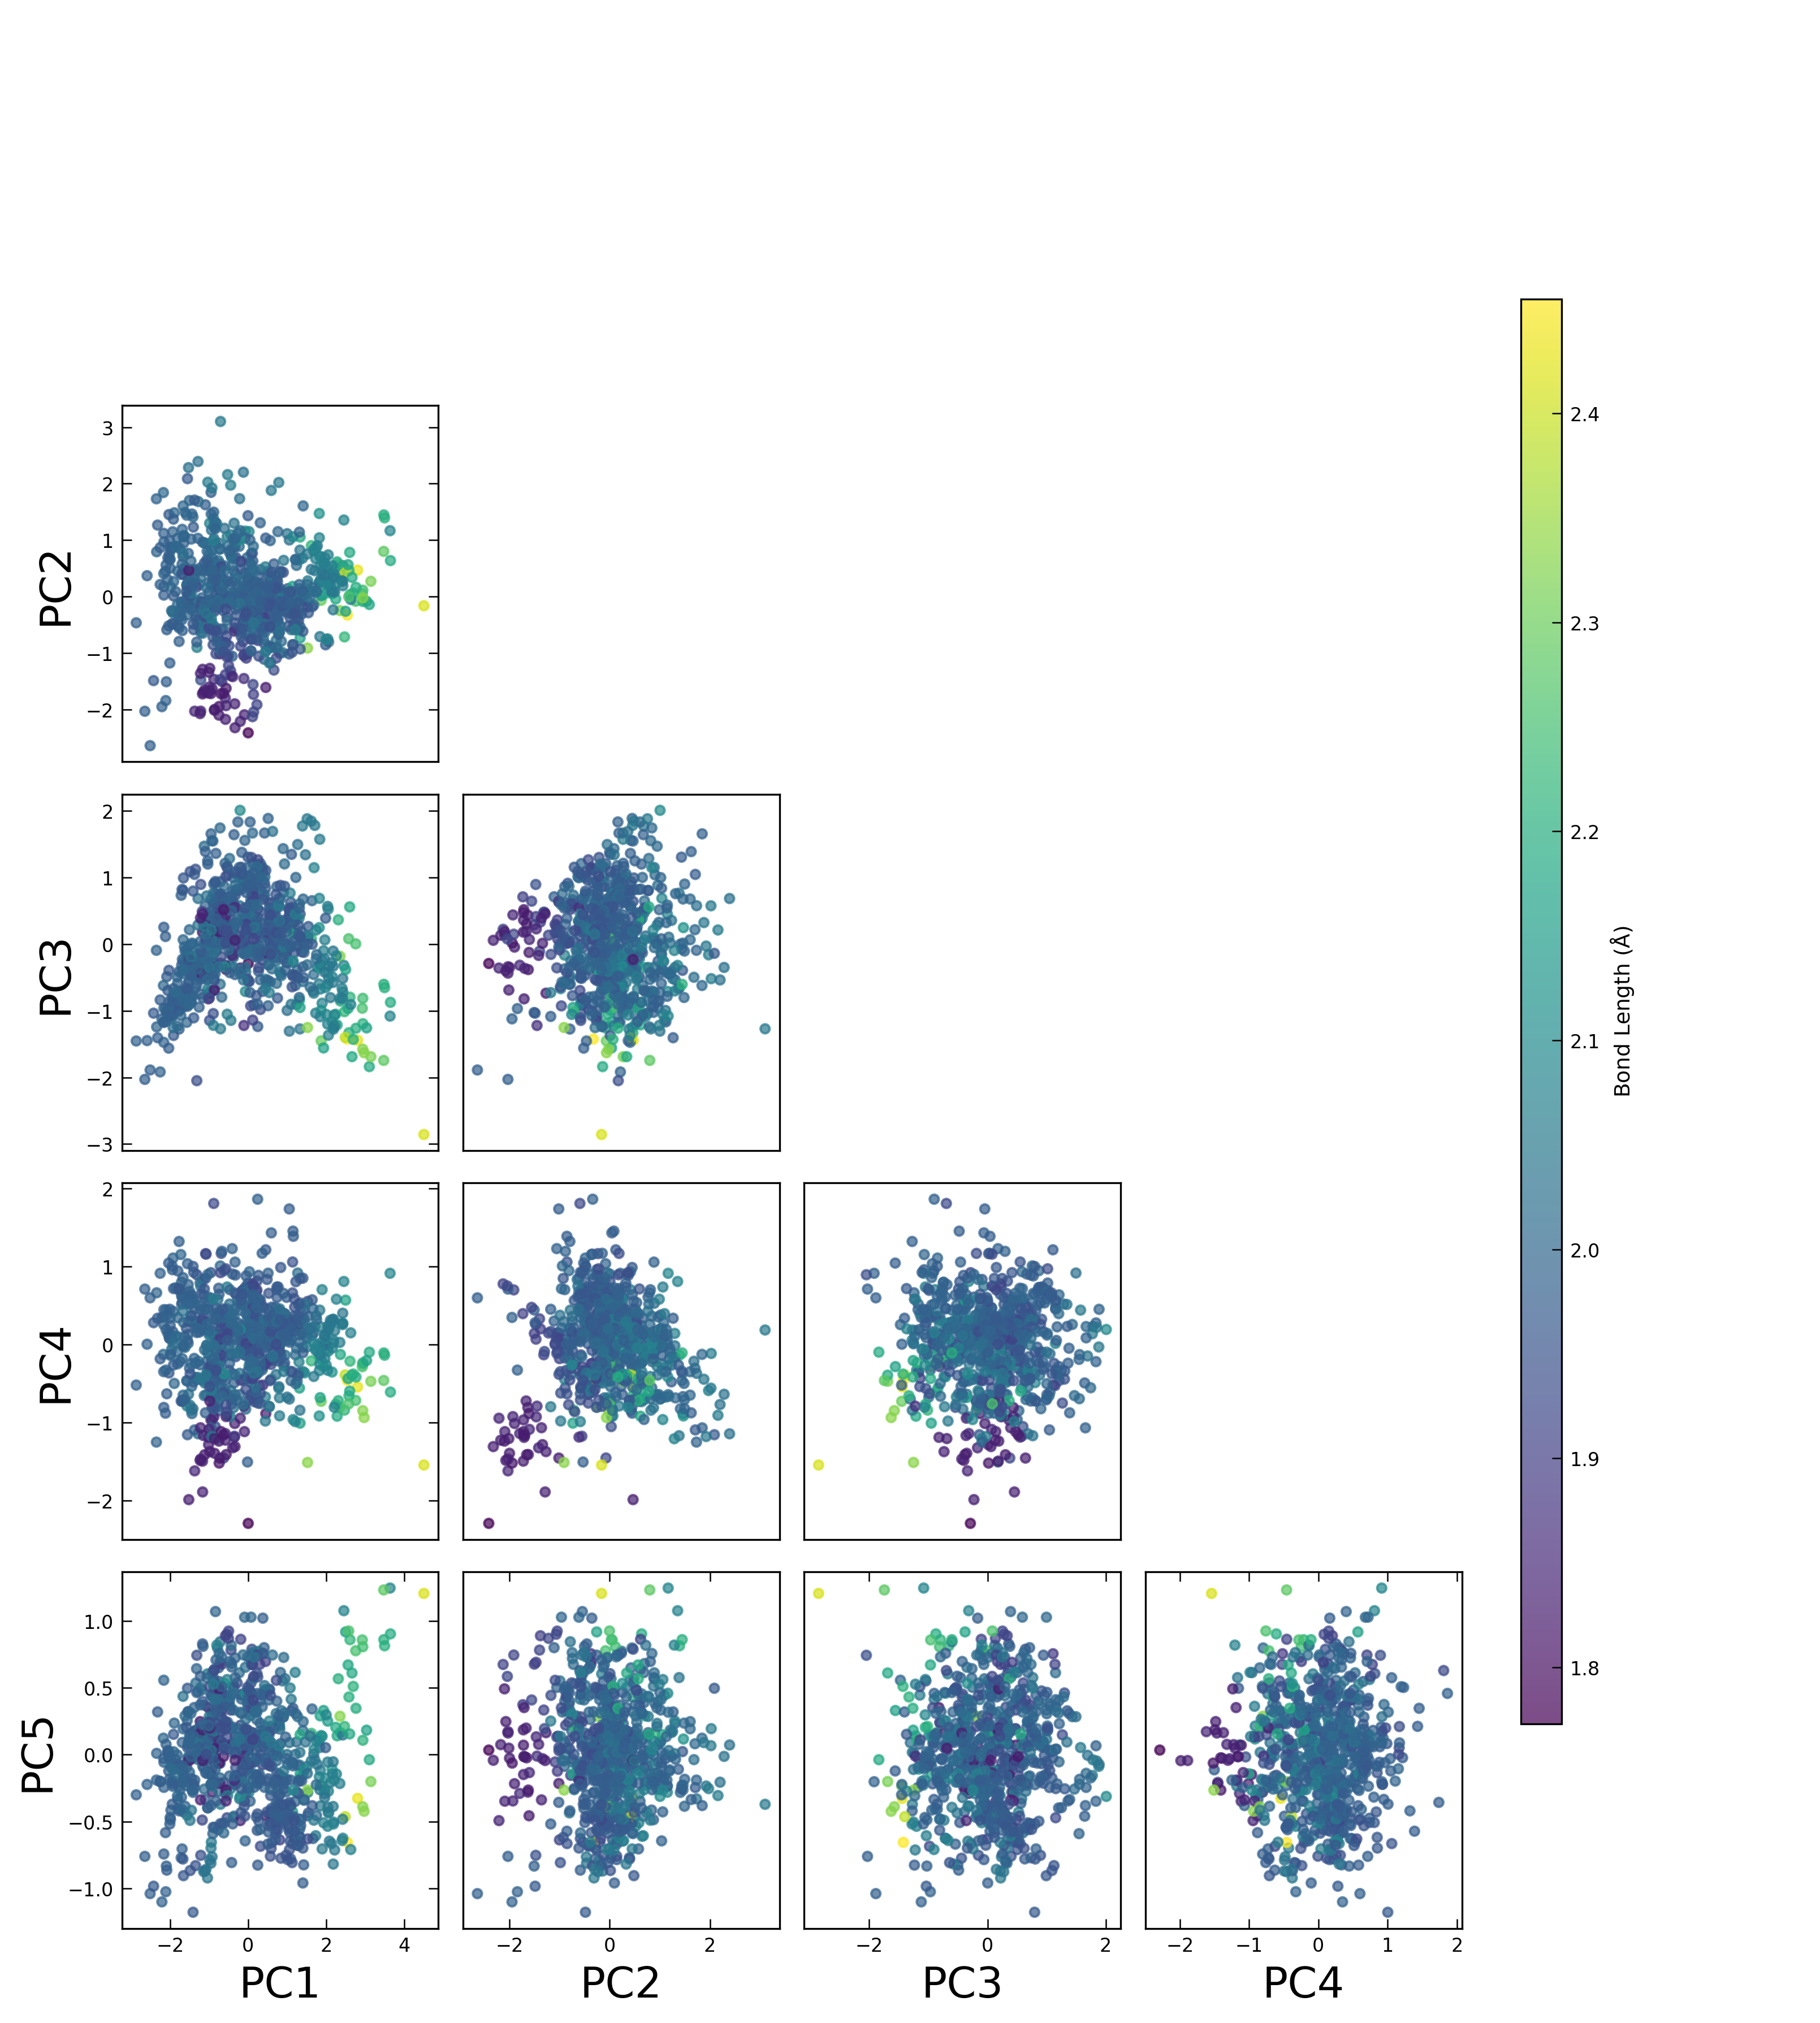

In [141]:
import matplotlib.pyplot as plt

pcs = ss.xanes_pca
labels = ss.nn

n_pcs = 5  # first 5 PCs
fig, axes = plt.subplots(n_pcs, n_pcs, figsize=(12, 12))#, sharex='col', sharey='row')

sc = None
for i in range(n_pcs):
    for j in range(n_pcs):
        ax = axes[i, j]
        if i < j:
            ax.axis("off")  # upper triangle: hide
        elif i == j:
            # Diagonal: histogram
            #ax.hist(pcs[:, i], bins=30, color="gray", alpha=0.7)
            ax.axis("off")
        else:
            # Lower triangle: scatter plot
            sc = ax.scatter(
                pcs[:, j], pcs[:, i],
                c=labels, cmap="viridis", s=15, alpha=0.7
            )
        # Axis labels
        if i == n_pcs - 1 and j <= i:
            ax.set_xlabel(f"PC{j+1}", size=18)
        else:
            ax.set_xticks([])
        if j == 0 and i > 0:
            ax.set_ylabel(f"PC{i+1}", size=18)
        else:
            ax.set_yticks([])

# Add one fixed colorbar on the right
cbar_ax = fig.add_axes([0.75, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
fig.colorbar(sc, cax=cbar_ax, label=r"Bond Length ($\AA$)", shrink=0.5, aspect=5)

plt.tight_layout(rect=[0, 0, 0.9, 1])  # leave space for colorbar
save_path = None
if save_path:
    plt.savefig(f"{save_path}/supplementary_xanes5pcs.svg")
    plt.savefig(f"{save_path}/supplementary_xanes5pcs.pdf")

